# Homework 3

Author: Khanh Do

Acknowledgement: Use of the internet to get domain knowledge and inspiration for classification workflow of the problem at hand. Some of the websites I've visited are https://www.pandasecurity.com/en/mediacenter/spam-text-message-examples/, https://medium.com/hackernoon/a-simple-spam-classifier-193a23666570, https://pubmed.ncbi.nlm.nih.gov/26403903/, https://www.geeksforgeeks.org/machine-learning/autocorrelation/, https://www.geeksforgeeks.org/machine-learning/quantiles-in-machine-learning/, https://www.sciencedirect.com/science/article/pii/S0001457516304419 mostly to inform my feature engineering but all code is of my own or  adapted from class materials. Comments and reflections language is improved by the help of Grammarly. ChatGPT was used to help explain/brainstorm the second question and verify the correction of my code.

### Imports

In [73]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import warnings   # Turns off the future warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score
from sklearn.base import clone
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV

## Question 1

The goal of this challenge is to obtain the best cross-validated F1 score for the SMS spam classification data set.

### 1. Read in Data

In [74]:
spam = pd.read_csv("https://remiller1450.github.io/data/sms_spam.txt", sep="\t", header=None, names=["label", "message"])
spam.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [75]:
# Separate predictors and outcome
spam_X = spam["message"]
spam_y = spam["label"].map({"ham": 0, "spam": 1})  # for classification

### 2. Explore Data

In [76]:
print("Data shape:", spam.shape)
print("N/A rows:", spam_X.isna().sum())
print("Empty rows:", spam_X.str.strip().eq("").sum())
print("Duplicate rows:", spam.duplicated().sum())

Data shape: (5572, 2)
N/A rows: 0
Empty rows: 0
Duplicate rows: 403


In [77]:
print(spam_y.value_counts())

label
0    4825
1     747
Name: count, dtype: int64


**Comment:** The data is imbalanced. F1 score will be used later.

In [78]:
print(spam.sample(25, random_state=5).to_string(index=False))

label                                                                                                                                                                  message
 spam                         PRIVATE! Your 2004 Account Statement for 07742676969 shows 786 unredeemed Bonus Points. To claim call 08719180248 Identifier Code: 45239 Expires
  ham                                                                                            No go. No openings for that room 'til after thanksgiving without an upcharge.
 spam          GENT! We are trying to contact you. Last weekends draw shows that you won a £1000 prize GUARANTEED. Call 09064012160. Claim Code K52. Valid 12hrs only. 150ppm 
  ham                                                                                                               Can you plz tell me the ans. BSLVYL sent via fullonsms.com
  ham                                                                                            I know girls always safe and

**Comment:** The spam messages often contain long phone number, monetary amounts, promotional language, instructions to call/reply and a sense of urgency. There is a lot of use of the exclamation mark ('!'), account-related words, and words to encourage action like "Expire", "CLaim", "Call", "Contact", etc. Ham messages seems more conversational, with typos, `...`, grammar errors, either extensive or none capitalization. Some contains links and seems shorter than spam. Thus, we should check for message length, word count, digit count, and exclamation mark count as the next exploration step. We can also count the number of money sign ('$', '£') and question mark sign ('?'). Capitalization is interesting, we can explore the proportion of capitalization letters to the whole text. These considerations will go into feature engineering later.

In [79]:
explore = spam.assign(
    message_length=spam_X.str.len(),
    word_count=spam_X.str.split().str.len(),
    digit_count=spam_X.str.count(r"\d"),
    exclamation_count=spam_X.str.count("!"),
    question_count=spam_X.str.count(r"\?"),
    smiley_count=spam_X.str.count(r":-?\)"),
    help_count=spam_X.str.count(r"(?i)\bhelp\b"),
    ur_count=spam_X.str.count(r"(?i)\bur\b")
)

display(explore.groupby("label")[["message_length", "word_count", "digit_count", "exclamation_count", "question_count", "smiley_count", "help_count", "ur_count"]].agg(["mean", "median"]))

message_length        word_count        digit_count         \
                mean median       mean median        mean median   
label                                                              
ham        71.482487   52.0  14.310259   11.0    0.305285    0.0   
spam      138.670683  149.0  23.911647   25.0   15.812584   16.0   

      exclamation_count        question_count        smiley_count         \
                   mean median           mean median         mean median   
label                                                                      
ham            0.176580    0.0       0.284974    0.0      0.07399    0.0   
spam           0.729585    0.0       0.234270    0.0      0.00000    0.0   

      help_count         ur_count         
            mean median      mean median  
label                                     
ham     0.007461    0.0  0.051192    0.0  
spam    0.029451    0.0  0.192771    0.0

**Comment:** Spam messages have longer length and more words. Spam messages have substantially more digits, which is consistent with what we saw previously. Although both spam and ham messages have a median of 0 for exclamation mark count, spam has more exclamation marks on average. The question mark count is pretty similar between ham and spam message, with ham message even have more on average. However, I'll retain this to see if combined with other features is meaningful. The smiley count (':-)') seems to only appear in ham messages.

### 3. Feature Engineering

In [80]:
def feature_engineering(input_text):
    text = input_text.fillna("")
    length = text.str.len()

    return pd.DataFrame({
        "message_length": length,
        "word_count": text.str.split().str.len(),
        "digit_count": text.str.count(r"\d"),
        "exclamation_count": text.str.count("!"),
        "question_count": text.str.count(r"\?"),

        "uppercase_proportion": (
            text.str.count(r"[A-Z]") / length.clip(lower=1)
        ),

        "has_link": text.str.contains(
            r"(?i)(?:https?://|www\.|\b[a-z0-9]+(?:-[a-z0-9]+)*"
            r"(?:\.[a-z0-9]+(?:-[a-z0-9]+)*)*"
            r"\.(?:com|org|net|co\.uk|uk|info|biz|mobi)\b)"
        ).astype(int),

        "has_currency": text.str.contains(
            r"[$£€]"
        ).astype(int),

        "has_phone_number": text.str.contains(
            r"(?<!\w)\+?\d(?:[ -]?\d){9,11}(?!\w)"
        ).astype(int),

        "account_word_count": text.str.count(
            r"(?i)\b(?:account|password|bank|banking|"
            r"login|verify|verification)\b"
        ),

        "promotion_word_count": text.str.count(
            r"(?i)\b(?:free|win|wins|won|winner|winners|selected|"
            r"prize|prizes|bonus|offers?|guaranteed|earn|"
            r"congratulations|congrats)\b"
        ),

        "action_word_count": text.str.count(
            r"(?i)\b(?:call|reply|claim|contact|text)\b"
        ),

        "urgency_word_count": text.str.count(
            r"(?i)\b(?:urgent|expires?|expiry|"
            r"immediately|deadline)\b"
        ),

        "has_smiley_face": text.str.contains(
            r"[:;]-?\)"
        ).astype(int),

        "help_word_count": text.str.count(
            r"(?i)\bhelp\b"
        ),
        
        "you_typo_count": text.str.count(
            r"(?i)\b(?:yur|ur|yuo|yoru)\b"
        )
    }, index=text.index)

In [81]:
# Check if this works
spam_X_FE = feature_engineering(spam_X)
display(spam_X_FE.sample(5, random_state=5))

,message_length,word_count,digit_count,exclamation_count,question_count,uppercase_proportion,has_link,has_currency,has_phone_number,account_word_count,promotion_word_count,action_word_count,urgency_word_count,has_smiley_face,help_word_count,you_typo_count
2095,144,20,34,1,0,0.111111,0,0,1,1,1,2,1,0,0,0
5343,77,13,0,0,0,0.025974,0,0,0,0,0,0,0,0,0,0
564,159,27,22,1,0,0.132075,0,1,1,0,3,3,0,0,0,0
3849,58,11,0,0,0,0.120690,1,0,0,0,0,0,0,0,0,0
3317,77,16,0,0,0,0.025974,0,0,0,0,0,0,0,0,0,0


**Comment:** Manual features that we just engineered are a start but we omit most vocabulary. I will add [CountVectorizer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.CountVectorizer.html). It learns a vocabulary and creates a feature for each token. We will also need to use [FeatureUnion](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.FeatureUnion.html) to apply both the manual and vectorized words transformations.

In [82]:
from sklearn.preprocessing import FunctionTransformer
from sklearn.feature_extraction.text import CountVectorizer
def make_combined_features():
    return FeatureUnion([
        ("manual", FunctionTransformer(feature_engineering)),
        ("words", CountVectorizer(
                    binary=True, # binary presence 0/1 (instead of occurence counts)
                    ngram_range=(1, 1) # uses individual words
                ))
    ])

### 4. Compare tree models

Let's compare random forest and XGBoost.

#### a. Random Forest

**Randomized search**

In [83]:
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline([
    ("features", make_combined_features()),
    ("model", RandomForestClassifier(n_estimators=300, random_state=5, n_jobs=1))
])

rf_params = {
    "model__max_depth": [5, 10, 20, None],
    "model__max_features": ["sqrt", 0.05, 0.1, 0.5],
    "model__min_samples_leaf": [1, 2, 5, 10],
    "model__class_weight": [None, "balanced"]
}

rf_search = RandomizedSearchCV(
    rf_pipeline, 
    param_distributions=rf_params,
    n_iter=30, 
    scoring="f1", 
    cv=5, 
    n_jobs=-1, 
    random_state=5
).fit(spam_X, spam_y)

print("Random Forest:")
print(rf_search.best_score_)
print(rf_search.best_params_)

Random Forest:
0.9565885650817159
{'model__min_samples_leaf': 1, 'model__max_features': 0.1, 'model__max_depth': 20, 'model__class_weight': 'balanced'}


**Grid search**

In [84]:
# Smaller pool to do grid search
rf_params_refined = {
    "model__max_depth": [20, None],
    "model__max_features": ["sqrt", 0.05, 0.1],
    "model__min_samples_leaf": [1, 2],
    "model__class_weight": [None, "balanced"]
}

rf_refined = GridSearchCV(
    rf_pipeline,
    param_grid=rf_params_refined, 
    scoring="f1", 
    cv=5, 
    n_jobs=-1
).fit(spam_X, spam_y)

print("Random Forest (refined search):")
print(rf_refined.best_score_)
print(rf_refined.best_params_)


Random Forest (refined search):
0.9631350199800558
{'model__class_weight': 'balanced', 'model__max_depth': 20, 'model__max_features': 0.05, 'model__min_samples_leaf': 1}


#### b. XGBoost

**Randomized search**

In [85]:
xgb_pipeline = Pipeline([
    ("features", make_combined_features()),
    ("model", xgb.XGBClassifier(eval_metric="logloss", random_state=5, n_jobs=1))
])

xgb_params = {
    "model__n_estimators": [100, 300, 500, 1000],
    "model__learning_rate": [0.05, 0.03, 0.01, 0.1],
    "model__max_depth": [2, 4, 6, 8],
    "model__min_child_weight": [1, 5, 10, 20],
    "model__subsample": [0.5, 0.75, 1.0],
    "model__colsample_bytree": [0.1, 0.5, 0.75, 1.0]
}

xgb_search = RandomizedSearchCV(
    xgb_pipeline,
    param_distributions=xgb_params,
    n_iter=30,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    random_state=5
).fit(spam_X, spam_y)

print("XGBoost:")
print(xgb_search.best_score_)
print(xgb_search.best_params_)

XGBoost:
0.9619813538054283
{'model__subsample': 0.75, 'model__n_estimators': 500, 'model__min_child_weight': 1, 'model__max_depth': 6, 'model__learning_rate': 0.05, 'model__colsample_bytree': 0.1}


**Grid search**

In [86]:
# Smaller pool to do grid search
xgb_params_refined = {
    "model__n_estimators": [500, 1000, 1500],
    "model__learning_rate": [0.01, 0.03, 0.05],
    "model__max_depth": [5, 6],
    "model__min_child_weight": [1],
    "model__subsample": [0.75, 1.0],
    "model__colsample_bytree": [0.1, 0.5]
}

xgb_refined = GridSearchCV(
    xgb_pipeline,
    param_grid=xgb_params_refined,
    scoring="f1",
    cv=5,
    n_jobs=-1
).fit(spam_X, spam_y)

print("XGBoost (refined search):")
print(xgb_refined.best_score_)
print(xgb_refined.best_params_)

XGBoost (refined search):
0.9642752683895506
{'model__colsample_bytree': 0.5, 'model__learning_rate': 0.03, 'model__max_depth': 6, 'model__min_child_weight': 1, 'model__n_estimators': 500, 'model__subsample': 1.0}


### 5. Compare selected configurations across fold assignments

The two models had similar default-fold performance (`best_score=0.96`). Following the homework’s suggestion to try different fold assignments, I will evaulate both best estimators using the same shuffled five-fold splits. 

In [87]:
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import f1_score, precision_score, recall_score

models = {"Random forest": rf_refined.best_estimator_,
          "XGBoost": xgb_refined.best_estimator_}

# Default folds plus three shuffled assignments (fav seed numbers)
fold_settings = {
    "Default": 5,
    "Seed 3": KFold(n_splits=5, shuffle=True, random_state=3),
    "Seed 55": KFold(n_splits=5, shuffle=True, random_state=55),
    "Seed 67": KFold(n_splits=5, shuffle=True, random_state=67)
}

results = []

for fold_name, folds in fold_settings.items():
    for model_name, model in models.items():
        pred = cross_val_predict(model, spam_X, spam_y, cv=folds, n_jobs=-1)
        results.append({
            "Model": model_name, "Folds": fold_name,
            "F1": f1_score(spam_y, pred)
        })
        
comparison = pd.DataFrame(results)
display(comparison)

for name, model in models.items(): 
    print(name, model.named_steps["model"])

,Model,Folds,F1
0,Random forest,Default,0.963215
1,XGBoost,Default,0.964286
2,Random forest,Seed 3,0.960000
3,XGBoost,Seed 3,0.962355
4,Random forest,Seed 55,0.963265
5,XGBoost,Seed 55,0.959506
6,Random forest,Seed 67,0.960000
7,XGBoost,Seed 67,0.956879


Random forest RandomForestClassifier(class_weight='balanced', max_depth=20, max_features=0.05,
                       n_estimators=300, n_jobs=1, random_state=5)
XGBoost XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.5, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.03, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=1, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=500, n_jobs=1,
              num_parallel_tree=None, ...)


**Comment:** Both models performed similarly across the evaluated fold assignments. I will select random forest because it achieved a slightly higher average F1 and more consistent F1 scores across the four tested fold assignments, although XGBoost achieved the highest default-fold F1.

### 6. Standalone final evaluation of one fixed pipeline

5-fold F1: 0.9632152588555858


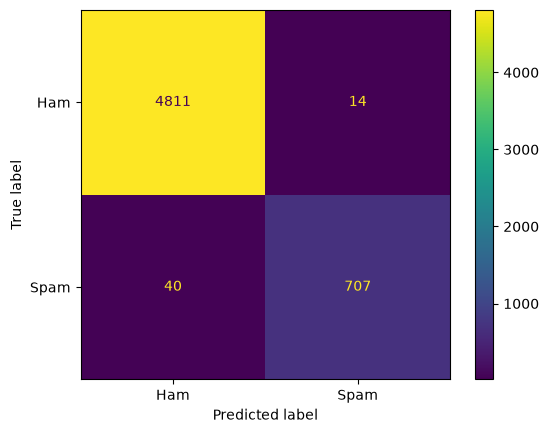

In [88]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.preprocessing import FunctionTransformer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import f1_score, precision_score, recall_score, ConfusionMatrixDisplay

def feature_engineering(input_text):
    text = input_text.fillna("")
    length = text.str.len()

    return pd.DataFrame({
        "message_length": length,
        "word_count": text.str.split().str.len(),
        "digit_count": text.str.count(r"\d"),
        "exclamation_count": text.str.count("!"),
        "question_count": text.str.count(r"\?"),

        "uppercase_proportion": (
            text.str.count(r"[A-Z]") / length.clip(lower=1)
        ),

        "has_link": text.str.contains(
            r"(?i)(?:https?://|www\.|\b[a-z0-9]+(?:-[a-z0-9]+)*"
            r"(?:\.[a-z0-9]+(?:-[a-z0-9]+)*)*"
            r"\.(?:com|org|net|co\.uk|uk|info|biz|mobi)\b)"
        ).astype(int),

        "has_currency": text.str.contains(
            r"[$£€]"
        ).astype(int),

        "has_phone_number": text.str.contains(
            r"(?<!\w)\+?\d(?:[ -]?\d){9,11}(?!\w)"
        ).astype(int),

        "account_word_count": text.str.count(
            r"(?i)\b(?:account|password|bank|banking|"
            r"login|verify|verification)\b"
        ),

        "promotion_word_count": text.str.count(
            r"(?i)\b(?:free|win|wins|won|winner|winners|selected|"
            r"prize|prizes|bonus|offers?|guaranteed|earn|"
            r"congratulations|congrats)\b"
        ),

        "action_word_count": text.str.count(
            r"(?i)\b(?:call|reply|claim|contact|text)\b"
        ),

        "urgency_word_count": text.str.count(
            r"(?i)\b(?:urgent|expires?|expiry|"
            r"immediately|deadline)\b"
        ),

        "has_smiley_face": text.str.contains(
            r"[:;]-?\)"
        ).astype(int),

        "help_word_count": text.str.count(
            r"(?i)\bhelp\b"
        ),
        
        "you_typo_count": text.str.count(
            r"(?i)\b(?:yur|ur|yuo|yoru)\b"
        )
    }, index=text.index)
    
def make_combined_features():
    return FeatureUnion([
        ("manual", FunctionTransformer(feature_engineering)),
        ("words", CountVectorizer(binary=True, ngram_range=(1, 1)))
    ])

# Read in data 
spam = pd.read_csv("https://remiller1450.github.io/data/sms_spam.txt",
                   sep="\t", header=None, names=["label", "message"])
spam_X = spam["message"]
spam_y = spam["label"].map({"ham": 0, "spam": 1})

# Chosen pipeline
final_pipeline = Pipeline([
    ("features", make_combined_features()),
    ("model", RandomForestClassifier(
        n_estimators=300,
        max_depth=20, 
        max_features=0.05,
        min_samples_leaf=1, 
        class_weight="balanced", 
        random_state=5, 
        n_jobs=1
    ))
])

final_predictions = cross_val_predict(final_pipeline, spam_X, spam_y, cv=5, n_jobs=-1)

print("5-fold F1:", f1_score(spam_y, final_predictions))
ConfusionMatrixDisplay.from_predictions(spam_y, final_predictions, display_labels=["Ham", "Spam"])
plt.show()

### 7. Modeling Philosophy and Choices

I represented each SMS message using manually engineered features and binary unigram indicators. Message inspection and class summaries motivated length, word and digit counts, punctuation, capitalization, currency, links, phone numbers, keyword groups, and smiley features. These manual feature engineering choices come from inspecting a random sample of spam/ham messages and assessing their average and median count. Because these summaries omit most vocabulary, I then used `CountVectorizer` to extract word-presence features and `FeatureUnion` to combine them with the manual features. I actually had some testing not included in this script that did not include `CountVectorize` and could not achieve an F1 score above 0.95. Then I did more research about `sklearn` and found this helpful tool. All transformations were placed inside pipelines so each training fold learned its own vocabulary. I compared random forest and XGBoost on this common representation, tuning hyperparameters with 5-fold spam F1 because spam is the minority class and both missed spam and false alarms matter. Random forest tuning included feature subsampling, depth, leaf size, and class weights; XGBoost tuning included learning rate, tree count, depth, child weight, and sampling. Scaling and PCA were not considered because they were not needed for the chosen tree pipelines. I compared random forest and XGBoost because both can capture nonlinear relationships and interactions between manually engineered features and word-presence indicators. They also provide contrasting ensemble approaches. I limited the comparison to these two model families, so the selected model is the best among the configurations evaluated rather than necessarily the best possible classifier. I checked selected configurations across several fold assignments and evaluated one fixed final pipeline using `cross_val_predict`. Although the chosen XGBoost model achieve the highest default-fold F1, I chose the random forest settings as my final classification because it achieved a slightly higher average F1 and more consistent scores across the four tested fold assignments. The disadvantage of my workflow is I do not know how it will perform on an unseen test set. Some manual feature I selected is specific to this dataset (e.g., only ham message has smiley face notation).

## Question 2

The goal of this challenge is to obtain the best ROC-AUC score on a time-series classification task.

### 1. Read in data

In [89]:
drug = pd.read_csv("https://remiller1450.github.io/data/drugdetection.csv")
drug.head()

,ID,Full_Sample_ID,DosingLevel,Target,CFS.Brake.Pedal.Force,CFS.Accelerator.Pedal.Position,CFS.Steering.Wheel.Angle,CFS.Steering.Wheel.Angle.Rate,SCC.Lane.Deviation.2,VDS.Veh.Speed
0,34,34_1_YM,YM,1,0.030653,0.383080,2.021470,3.345467,-5.376608,71.282471
1,34,34_1_YM,YM,1,-0.007314,0.385061,2.109360,3.961737,-5.422563,71.281548
2,34,34_1_YM,YM,1,-0.007314,0.386401,2.153305,3.961737,-5.469440,71.281052
3,34,34_1_YM,YM,1,0.002178,0.387513,2.197250,4.049776,-5.517264,71.280991
4,34,34_1_YM,YM,1,0.011669,0.388236,2.285140,3.521544,-5.564104,71.281364


Columns:
- `CFS.Brake.Pedal.Force` - Force (J) recorded on the brake pedal.
- `CFS.Accelerator.Pedal.Position` - The percent depression of the accelerator pedal (a value of 1 is 100% depressed or “pedal to the floor”).
- `CFS.Steering.Wheel.Angle` - The angle of the steering wheel relative to neutral.
- `CFS.Steering.Wheel.Angle.Rate` - The instantaneous rate of change in the steering wheel angle.
- `SCC.Lane.Deviation.2` - Lateral displacement of the center of the vehicle from the center of the lane. A value of 0 means the vehicle’s center is exactly in the center of the lane.
- `VDS.Veh.Speed` - Speed of the vehicle in miles per hour.
- `ID` - The participant ID, you may opt to use this as a variable to facilitate driver-specific effects, but the guide advises against retaining it as a numeric variable.

### 2. Explore Data

In [90]:
print('Data shape:', drug.shape)
print('Missing values:', drug.isna().sum().sum())

drug_groups = drug.groupby('Full_Sample_ID', sort=False)
print("\n")
print('Time steps per sample:')
print(drug_groups.size().value_counts())
print("\n")
print('Class counts:')
print(drug_groups['Target'].first().value_counts())

Data shape: (608400, 10)
Missing values: 0


Time steps per sample:
3600    169
Name: count, dtype: int64


Class counts:
Target
1    111
0     58
Name: count, dtype: int64


**Comment:** There are 608400 rows but only 169 driver samples. Each sample contains 3600 time steps. There are 111 active drug samples and 58 placebo samples. No missing value in the dataset. Each drive must become one row before CV.

In [91]:
drug_signals = {
    "brake": "CFS.Brake.Pedal.Force",
    "accelerator": "CFS.Accelerator.Pedal.Position",
    "steering": "CFS.Steering.Wheel.Angle",
    "steering_rate": "CFS.Steering.Wheel.Angle.Rate",
    "lane": "SCC.Lane.Deviation.2",
    "speed": "VDS.Veh.Speed"
}
display(drug[list(drug_signals.values())].describe().T)

,count,mean,std,min,25%,50%,75%,max
CFS.Brake.Pedal.Force,608400.0,0.456706,3.004246,-1.996782,-0.025443,0.009202,0.047359,82.914910
CFS.Accelerator.Pedal.Position,608400.0,0.351551,0.221242,0.000000,0.225816,0.325069,0.447812,1.104237
CFS.Steering.Wheel.Angle,608400.0,-0.406155,3.087301,-16.127810,-2.460920,-1.406240,1.186515,13.271390
CFS.Steering.Wheel.Angle.Rate,608400.0,0.426783,4.586597,-94.641500,-0.616270,0.352154,1.408618,83.548630
SCC.Lane.Deviation.2,608400.0,-0.010226,1.324080,-5.999821,-0.817188,-0.047389,0.779111,6.028944
VDS.Veh.Speed,608400.0,66.619772,6.891687,25.398100,63.743547,67.183567,70.838337,97.498560


**Comment:** Here's what I see from the grouped summarization.
- For `brake`, the median is 0.009 but the max is very high, 82.9. Seems like the usual value is around 0 with occasional large spikes. So we should not rely on average braking alone.
- For `steering_rate`, there are extremes on both ends (min of -94.6 and max of 83.5) while most values are between -0.62 and 1.41. This motivates short-window variability features to capture sudden steering changes.
- For `lane`, the mean is -0.01 (near 0) but this does not mean steady lane keeping and standard deviation and rolling variability might be more helpful.
- For `speed`, the mean is 66.6, below the posted speed limit of 70 mph, but min is 25.4 and max is 97.5 and so we might use speed variability and we should look into the proportions of measurements > 70.

Overall, there is some pattern that motivates features describing variability, deviations and short rolling window.

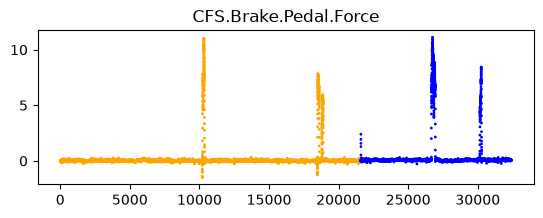

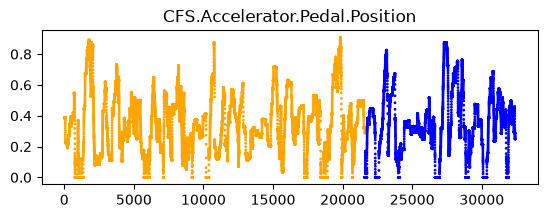

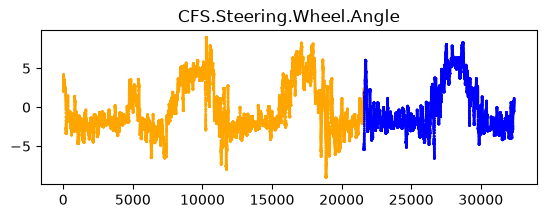

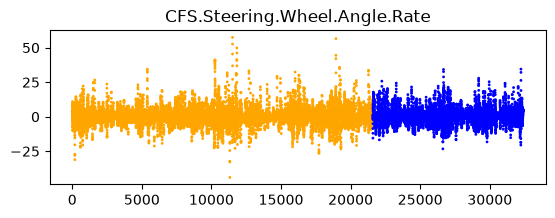

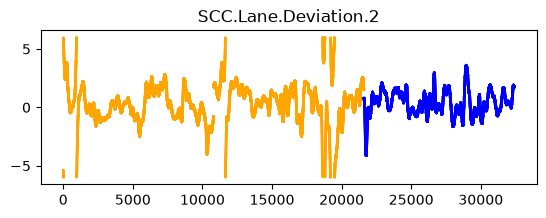

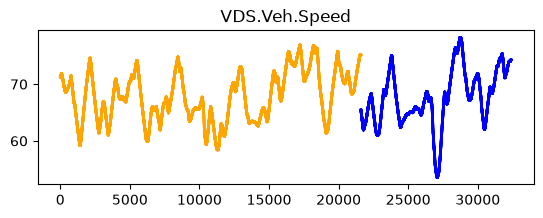

In [92]:
# Choose the first participant
driver = drug['ID'].iloc[0]
drug_plot = drug[drug['ID'] == driver]

# Create plots of signals over time and color by condition
my_vars = [
    'CFS.Brake.Pedal.Force',
    'CFS.Accelerator.Pedal.Position',
    'CFS.Steering.Wheel.Angle',
    'CFS.Steering.Wheel.Angle.Rate',
    'SCC.Lane.Deviation.2',
    'VDS.Veh.Speed'
]

for cur_var in my_vars:
    plt.figure().set_figheight(2)
    plt.scatter(
        x=range(len(drug_plot)),
        y=drug_plot[cur_var],
        c=drug_plot['Target'].map({0: 'blue', 1: 'orange'}),
        s=1
    )
    plt.title(cur_var)
    plt.show()

**Comment:** The plots are consistent with the summary statistics: braking and steering rate show occasional sharp changes, while lane deviation varies throughout the drives. The lane plot is difficult to interpret because it combines multiple samples. Next, I will examine lane deviation within one 60-second sample.


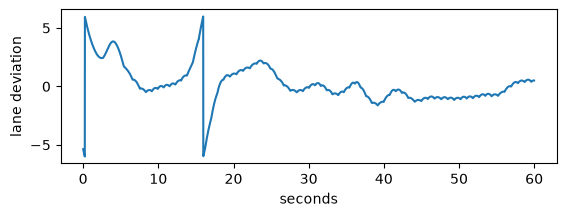

In [93]:
# Look into lane deviation within one 60-second sample
sample_id = drug_plot['Full_Sample_ID'].iloc[0]
sample = drug_plot[drug_plot['Full_Sample_ID'] == sample_id]

plt.figure().set_figheight(2)
plt.plot(np.arange(len(sample)) / 60, sample['SCC.Lane.Deviation.2'])
plt.xlabel('seconds')
plt.ylabel('lane deviation')
plt.show()

**Comment:** This plot shows lane deviation for one 60-second drive. The signal changes over the drive, so a single average would not describe all of its variation. One example cannot be reliable though.

### 3. Feature Engineering

I will focus on steering angle, steering rate, and lane deviation because they describe steering control and lane position. I will summarize their typical values, variability, and changes over time to capture patterns that may not be visible from their averages alone. Not included in this notebook but previously I had a set with features from all six signals and the results were not as good as this focused set of three signals.

In [94]:
from scipy.stats import linregress
def window_features(x, seconds):
    # At 60 measurements per second, 60 * seconds => window size
    window_size = 60 * seconds
    time = np.arange(window_size) / 60
    slopes = []
    standard_deviations = []

    for start in range(0, len(x), window_size):
        window = x.iloc[start : start + window_size]
        
        # The slope describes how quickly the signal tends to change
        slopes.append(linregress(time, window).slope)  
        
        standard_deviations.append(window.std(ddof=0))  # ddof=0 to match np's default std

    # Don't care about direction
    absolute_slopes = np.abs(slopes)
    return {
        'slope_mean': np.mean(absolute_slopes),
        'slope_std': np.std(slopes),
        'slope_q90': np.quantile(absolute_slopes, 0.90),  # to not rely on max
        'window_std_mean': np.mean(standard_deviations),
        'window_std_max': np.max(standard_deviations)
    }

def summarize_signal(x):
    # Typical values and spread
    result = {
        'mean': x.mean(), 'median': x.median(), 'std': x.std(),
        'min': x.min(), 'max': x.max(),
        'q10': x.quantile(0.10), 'q90': x.quantile(0.90),
        'iqr': x.quantile(0.75) - x.quantile(0.25),
        'rms': np.sqrt(x.pow(2).mean()),
        'change_mean': x.diff().abs().mean(),  # typical size of a measurement-to-measurement change
        'change_1sec': x.diff(60).abs().mean(),  # averages the size of one-second changes
        'rolling_std': x.rolling(60).std().mean(),  # average variation in overlapping one-second windows
    }

    # Compare changes over short (1s), medium (5s), and longer (10s) sections of the drive
    for seconds in [1, 5, 10]:
        window = window_features(x, seconds)
        result[f'slope_{seconds}s_mean'] = window['slope_mean']
        result[f'slope_{seconds}s_std'] = window['slope_std']
        result[f'slope_{seconds}s_q90'] = window['slope_q90']
        result[f'window_{seconds}s_std_mean'] = window['window_std_mean']
        result[f'window_{seconds}s_std_max'] = window['window_std_max']

    # Autocorrelation measures similarity to values 0.1, 1, and 5 seconds earlier
    for lag in [6, 60, 300]:
        result[f'autocorr_{lag}'] = x.autocorr(lag)  # correlation between x and x shifted by lag rows.
    return pd.Series(result)

# Distance from the lane center, don't care if it is left or right
def lane_features(x):
    return pd.Series({
        'lane_abs_mean': x.abs().mean(),
        'lane_abs_q90': x.abs().quantile(0.90)
    })

# Compare steering now with lane deviation at the same time or later
def steering_lane_correlation(sample, steering_column, lag):
    # drop=True prevents the old index from becoming a column.
    steering = sample[steering_column].reset_index(drop=True)
    lane = sample['SCC.Lane.Deviation.2'].reset_index(drop=True)
    
    # shift(-lag) lines up a later lane value with the current steering value
    # use corr() to measure their linear relationship
    return steering.corr(lane.shift(-lag))

The signals change over time, and nearby measurements may be related. I used autocorrelation to examine whether a signal tends to remain similar over short periods. I will also compare steering with lane deviation at the same time and after short delays via `steering_lane_correlation`, since a change in steering may be followed by a change in lane position.

In [95]:
def drug_feature_engineering(data):
    # Focused set
    signals = {
        'steering': 'CFS.Steering.Wheel.Angle',
        'steering_rate': 'CFS.Steering.Wheel.Angle.Rate',
        'lane': 'SCC.Lane.Deviation.2'
    }
    
    # Group the measurements belonging to the same 60-second drive
    # sort=False keeps sample IDs in the order appear in the data
    groups = data.groupby('Full_Sample_ID', sort=False)
    
    feature_tables = []

    # Go through each short name and its corresponding data column.
    for name, column in signals.items():
        # Apply the standard summarization features
        table = groups[column].apply(summarize_signal).unstack()  # unstack() rearranges the output so each sample is a row
        table.columns = [name + '_' + feature for feature in table.columns]
        feature_tables.append(table)

    # Apply the lane features
    lane_table = groups[signals['lane']].apply(lane_features).unstack()
    feature_tables.append(lane_table)

    # Compare steering, steering_rate with lane deviation.
    for name in ['steering', 'steering_rate']:
        # 0, 0.5 and 1 second delays
        for lag in [0, 30, 60]:
            # Apply the steering lane correlation features
            values = groups[[signals[name], signals['lane']]].apply(
                steering_lane_correlation, steering_column=signals[name], lag=lag
            )
            feature_tables.append(values.rename(f'{name}_lane_corr_{lag}').to_frame())

    # Join all feature tables
    result = pd.concat(feature_tables, axis=1)
    
    # Match the column order used when the final model was selected
    temp_words = ['_slope_', '_window_', '_autocorr_', '_corr_']
    basic = [col for col in result if not any(word in col for word in temp_words)]  # the rest
    temp = [col for col in result if col not in basic]
    
    return result[basic + temp]  # combined

In [96]:
# Verify that it works
drug_X = drug_feature_engineering(drug)
display(drug_X.head())

,steering_mean,steering_median,steering_std,steering_min,steering_max,steering_q10,steering_q90,steering_iqr,steering_rms,steering_change_mean,...,lane_window_10s_std_max,lane_autocorr_6,lane_autocorr_60,lane_autocorr_300,steering_lane_corr_0,steering_lane_corr_30,steering_lane_corr_60,steering_rate_lane_corr_0,steering_rate_lane_corr_30,steering_rate_lane_corr_60
Full_Sample_ID,,,,,,,,,,,,,,,,,,,,,
34_1_YM,-1.857933,-1.977525,1.402924,-4.658170,4.174775,-3.383765,-0.703120,1.230460,2.327996,0.043872,...,2.218422,0.907772,0.517181,0.150011,0.300672,0.325168,0.286842,-0.019385,0.004055,-0.040345
34_2_YM,-1.652076,-1.889635,1.855480,-6.459915,3.603490,-3.779270,1.274405,1.801745,2.484191,0.041625,...,1.366111,0.998593,0.924242,0.591218,-0.633192,-0.675404,-0.674270,0.056227,0.012537,-0.017037
34_3_YM,2.476105,3.515600,3.024325,-6.503860,8.964780,-1.538075,5.273400,3.735325,3.908337,0.055667,...,1.196729,0.998519,0.904362,0.362393,-0.519704,-0.516244,-0.461772,0.042394,-0.013271,-0.042127
34_1_ZM,-2.202328,-2.241195,1.676228,-7.997990,4.746060,-3.867160,-0.043945,1.274405,2.767528,0.048744,...,2.562577,0.935193,0.557675,-0.145237,0.072371,0.039533,0.002138,0.037680,0.012058,0.040332
34_2_ZM,1.940806,2.592755,3.442452,-4.130830,8.217714,-2.416975,6.284135,6.679639,3.951444,0.050624,...,1.410415,0.996724,0.773192,-0.001219,-0.251721,-0.274502,-0.223519,0.082806,-0.020829,-0.102848


### 4. Compare models

I compare KNN, random forest and XGBoost. I will also use [`SelectKBest(f_classif)`](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.SelectKBest.html), which ranks individual features by between-class differences relative to within-class variation.

Selection, imputation, and scaling occur inside each training fold. Scaling is useful for KNN and is kept in the shared pipeline for a consistent comparison but trees do not need it. The imputer handles undefined engineered correlations if they occur.

In [97]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

# drug_X calculated previously
drug_y = (
    drug.groupby('Full_Sample_ID', sort=False)['Target']
        .first()
        .reindex(drug_X.index)
)

drug_models = {
    'KNN': KNeighborsClassifier(),
    'Random forest': RandomForestClassifier(n_estimators=200, random_state=5, n_jobs=1),
    'XGBoost': XGBClassifier(random_state=5, n_jobs=1, eval_metric='logloss')
}

drug_params = {
    'KNN': {
        'select__k': [3, 5, 10, 20, 'all'],
        'model__n_neighbors': [5, 9, 15, 25, 35, 51],
        'model__weights': ['uniform', 'distance'],
        'model__p': [1, 2]
    },
    'Random forest': {
        'select__k': [3, 5, 10, 20, 'all'],
        'model__bootstrap': [True, False],
        'model__max_depth': [3, 5, 10, None],
        'model__max_features': ['sqrt', 0.5, 1.0],
        'model__min_samples_leaf': [1, 3, 5, 10]
    },
    'XGBoost': {
        'select__k': [3, 5, 10, 20, 'all'],
        'model__n_estimators': [100, 300, 500],
        'model__max_depth': [1, 2, 3],
        'model__learning_rate': [0.03, 0.1],
        'model__min_child_weight': [1, 5, 10],
        'model__subsample': [0.7, 1.0],
        'model__reg_lambda': [1, 10]
    }
}

drug_searches = {}
for name, model in drug_models.items():
    pipeline = Pipeline([
        ('impute', SimpleImputer()),
        ('scale', StandardScaler()),
        ('select', SelectKBest(f_classif)),
        ('model', model)
    ])

    # Test 40 randomly chosen combinations using five-fold ROC-AUC
    search = RandomizedSearchCV(
        pipeline, 
        drug_params[name], 
        n_iter=40, 
        scoring='roc_auc',
        cv=5, 
        random_state=5, 
        n_jobs=-1
    ).fit(drug_X, drug_y)
    drug_searches[name] = search
    print(name)
    print(search.best_score_)
    print(search.best_params_)
    print("\n")


KNN
0.6845280871960714
{'select__k': 5, 'model__weights': 'uniform', 'model__p': 1, 'model__n_neighbors': 35}


Random forest
0.6989160378488443
{'select__k': 5, 'model__min_samples_leaf': 3, 'model__max_features': 'sqrt', 'model__max_depth': 5, 'model__bootstrap': True}


XGBoost
0.6880569529284944
{'select__k': 5, 'model__subsample': 1.0, 'model__reg_lambda': 10, 'model__n_estimators': 300, 'model__min_child_weight': 5, 'model__max_depth': 3, 'model__learning_rate': 0.03}




### 5. Compare selected configurations across fold assignments

As you can see we follow pretty similar workflow from question 1.

In [98]:
from sklearn.metrics import roc_auc_score

# Take the best pipeline found for each model.
drug_candidates = {
    'KNN': drug_searches['KNN'].best_estimator_,
    'Random forest': drug_searches['Random forest'].best_estimator_,
    'XGBoost': drug_searches['XGBoost'].best_estimator_
}

# Default folds plus three shuffled assignments (some more fav seed numbers)
fold_settings = {
    "Default": 5,
    "Seed 3": KFold(n_splits=5, shuffle=True, random_state=3),
    "Seed 35": KFold(n_splits=5, shuffle=True, random_state=35),
    "Seed 607": KFold(n_splits=5, shuffle=True, random_state=607)
}

results = []

for fold_name, cv in fold_settings.items():
    for model_name, model in drug_candidates.items():
        probability = cross_val_predict(
            model, drug_X, drug_y, cv=cv,
            method='predict_proba', n_jobs=-1
        )[:, 1]
        results.append({
            'Model': model_name,
            'Folds': fold_name,
            'ROC-AUC': roc_auc_score(drug_y, probability)
        })

display(pd.DataFrame(results))

,Model,Folds,ROC-AUC
0,KNN,Default,0.679015
1,Random forest,Default,0.680180
2,XGBoost,Default,0.681578
3,KNN,Seed 3,0.579062
4,Random forest,Seed 3,0.567257
5,XGBoost,Seed 3,0.568267
6,KNN,Seed 35,0.642358
7,Random forest,Seed 35,0.677540
8,XGBoost,Seed 35,0.650047
9,KNN,Seed 607,0.619602


**Comment:** XGBoost had the highest default score by a small margin. I will select random forest because it had the highest average score across these four assignments and the highest mean fold search score. On seed 35, random forest has a very good score comparing to KNN and XGBoost (0.67).

In [ ]:
print(drug_candidates['Random forest'])

Pipeline(steps=[('impute', SimpleImputer()), ('scale', StandardScaler()),
                ('select', SelectKBest(k=5)),
                ('model',
                 RandomForestClassifier(max_depth=5, min_samples_leaf=3,
                                        n_estimators=200, n_jobs=1,
                                        random_state=5))])


### 6. Standalone final evaluation of a fixed pipeline

5-fold ROC-AUC: 0.6801801801801802


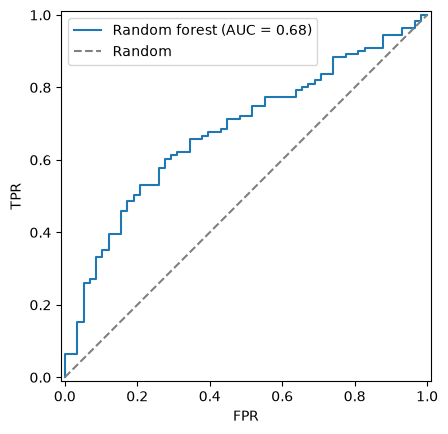

In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import linregress
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_auc_score

# Read in data
drug = pd.read_csv('https://remiller1450.github.io/data/drugdetection.csv')

# Feature engineer
from scipy.stats import linregress
def window_features(x, seconds):
    # At 60 measurements per second, 60 * seconds => window size
    window_size = 60 * seconds
    time = np.arange(window_size) / 60
    slopes = []
    standard_deviations = []

    for start in range(0, len(x), window_size):
        window = x.iloc[start : start + window_size]
        
        # The slope describes how quickly the signal tends to change
        slopes.append(linregress(time, window).slope)  
        
        standard_deviations.append(window.std(ddof=0))  # ddof=0 to match np's default std

    # Don't care about direction
    absolute_slopes = np.abs(slopes)
    return {
        'slope_mean': np.mean(absolute_slopes),
        'slope_std': np.std(slopes),
        'slope_q90': np.quantile(absolute_slopes, 0.90),  # to not rely on max
        'window_std_mean': np.mean(standard_deviations),
        'window_std_max': np.max(standard_deviations)
    }

def summarize_signal(x):
    # Typical values and spread
    result = {
        'mean': x.mean(), 'median': x.median(), 'std': x.std(),
        'min': x.min(), 'max': x.max(),
        'q10': x.quantile(0.10), 'q90': x.quantile(0.90),
        'iqr': x.quantile(0.75) - x.quantile(0.25),
        'rms': np.sqrt(x.pow(2).mean()),
        'change_mean': x.diff().abs().mean(),  # typical size of a measurement-to-measurement change
        'change_1sec': x.diff(60).abs().mean(),  # averages the size of one-second changes
        'rolling_std': x.rolling(60).std().mean(),  # average variation in overlapping one-second windows
    }

    # Compare changes over short (1s), medium (5s), and longer (10s) sections of the drive
    for seconds in [1, 5, 10]:
        window = window_features(x, seconds)
        result[f'slope_{seconds}s_mean'] = window['slope_mean']
        result[f'slope_{seconds}s_std'] = window['slope_std']
        result[f'slope_{seconds}s_q90'] = window['slope_q90']
        result[f'window_{seconds}s_std_mean'] = window['window_std_mean']
        result[f'window_{seconds}s_std_max'] = window['window_std_max']

    # Autocorrelation measures similarity to values 0.1, 1, and 5 seconds earlier
    for lag in [6, 60, 300]:
        result[f'autocorr_{lag}'] = x.autocorr(lag)  # correlation between x and x shifted by lag rows.
    return pd.Series(result)

# Distance from the lane center, don't care if it is left or right
def lane_features(x):
    return pd.Series({
        'lane_abs_mean': x.abs().mean(),
        'lane_abs_q90': x.abs().quantile(0.90)
    })

# Compare steering now with lane deviation at the same time or later
def steering_lane_correlation(sample, steering_column, lag):
    # drop=True prevents the old index from becoming a column.
    steering = sample[steering_column].reset_index(drop=True)
    lane = sample['SCC.Lane.Deviation.2'].reset_index(drop=True)
    
    # shift(-lag) lines up a later lane value with the current steering value
    # use corr() to measure their linear relationship
    return steering.corr(lane.shift(-lag))

def drug_feature_engineering(data):
    # Focused set
    signals = {
        'steering': 'CFS.Steering.Wheel.Angle',
        'steering_rate': 'CFS.Steering.Wheel.Angle.Rate',
        'lane': 'SCC.Lane.Deviation.2'
    }
    
    # Group the measurements belonging to the same 60-second drive
    # sort=False keeps sample IDs in the order appear in the data
    groups = data.groupby('Full_Sample_ID', sort=False)
    
    feature_tables = []

    # Go through each short name and its corresponding data column.
    for name, column in signals.items():
        # Apply the standard summarization features
        table = groups[column].apply(summarize_signal).unstack()  # unstack() rearranges the output so each sample is a row
        table.columns = [name + '_' + feature for feature in table.columns]
        feature_tables.append(table)

    # Apply the lane features
    lane_table = groups[signals['lane']].apply(lane_features).unstack()
    feature_tables.append(lane_table)

    # Compare steering, steering_rate with lane deviation.
    for name in ['steering', 'steering_rate']:
        # 0, 0.5 and 1 second delays
        for lag in [0, 30, 60]:
            # Apply the steering lane correlation features
            values = groups[[signals[name], signals['lane']]].apply(
                steering_lane_correlation, steering_column=signals[name], lag=lag
            )
            feature_tables.append(values.rename(f'{name}_lane_corr_{lag}').to_frame())

    # Join all feature tables side by side
    result = pd.concat(feature_tables, axis=1)
    
    # Match the column order used when the final model was selected
    temp_words = ['_slope_', '_window_', '_autocorr_', '_corr_']
    basic = [col for col in result if not any(word in col for word in temp_words)]
    temp = [col for col in result if col not in basic]
    
    return result[basic + temp]

# Selected model and configs
final_pipeline = Pipeline([
    ('impute', SimpleImputer()),
    ('scale', StandardScaler()),
    ('select', SelectKBest(f_classif, k=5)),
    ('model', RandomForestClassifier(
        n_estimators=200, 
        max_depth=5, 
        max_features='sqrt',
        min_samples_leaf=3, 
        bootstrap=True, 
        random_state=5, 
        n_jobs=1
    ))
])

drug_X = drug_feature_engineering(drug)
drug_y = (
    drug.groupby('Full_Sample_ID', sort=False)['Target']
        .first()
        .reindex(drug_X.index)
)

# Use predict_proba for roc-auc
probability = cross_val_predict(
    final_pipeline, drug_X, drug_y, cv=5, method='predict_proba', n_jobs=-1
)[:, 1]
print('5-fold ROC-AUC:', roc_auc_score(drug_y, probability))
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

# Plot the ROC curve using the out-of-fold probabilities.
RocCurveDisplay.from_predictions(
    drug_y,
    probability,
    name='Random forest'
)
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.legend()
plt.show()

### 7. Modeling philosophy and choices

I represented each 60-second drive using features from steering angle, steering rate, and lane deviation. I chose these signals because they describe how the driver controls the vehicle and how the vehicle moves within the lane. For each signal, I calculated measures of typical values and spread, including the mean, standard deviation, percentiles, and interquartile range. I also calculated changes between measurements and average one-second rolling variability because an overall average may hide brief changes during a drive. To describe changes over different periods, I fitted a line within consecutive 1, 5, and 10 seconds windows and summarized the slopes and standard deviations. This idea was inspired by https://doi.org/10.1016/j.jsr.2015.06.007. They used slopes of steering-angle and lateral-position segments to study impaired driving. My fixed-window approach is simpler and does not reproduce their method. I also included autocorrelations to measure how similar each signal was to its earlier values, and correlations between steering and lane deviation at short delays to explore whether steering patterns were related to later vehicle position. I compared KNN, random forest, and XGBoost using randomized searches and five-fold ROC-AUC. I placed imputation, scaling, feature selection, and the model in a pipeline so that the preprocessing steps were fitted separately within each training fold. Scaling was useful for KNN because it relies on distances; the tree models did not need it, but I kept it for consistency. I selected random forest because it had the highest mean fold search score and the highest average pooled AUC across the fold assignments I checked, although XGBoost had a slightly higher default-fold AUC. The selected forest uses five features per fold, 200 trees, a maximum depth of 5, and a minimum of three samples per leaf. Its performance varied across shuffled folds, which suggests that the results are sensitive to how the dataset is divided. The disadvantage of my workflow is I do not know how it will perform on an unseen test set. Similar to question 1, I used the same data to explore features and select the model.